In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent.parent
sys.path.append(str(project_root))

from ebm.data.toy import sample_eight_gaussians
from ebm.models.energy_model import EnergyModel


data = sample_eight_gaussians(
    n_samples=1000,
    seed=42,
)

model = EnergyModel()

energy = model(data)

print(data.shape)
print(energy.shape)

print(data[:5])
print(energy[:5])

torch.Size([1000, 2])
torch.Size([1000])
tensor([[-0.0621, -2.0793],
        [-1.4904,  1.5864],
        [-1.9640, -0.1186],
        [-0.1220, -1.9788],
        [ 0.2345,  2.0897]])
tensor([-0.0123, -0.0194, -0.0319, -0.0064,  0.1130], grad_fn=<SliceBackward0>)


In [2]:
import numpy as np

print(np.__version__)

2.5.2


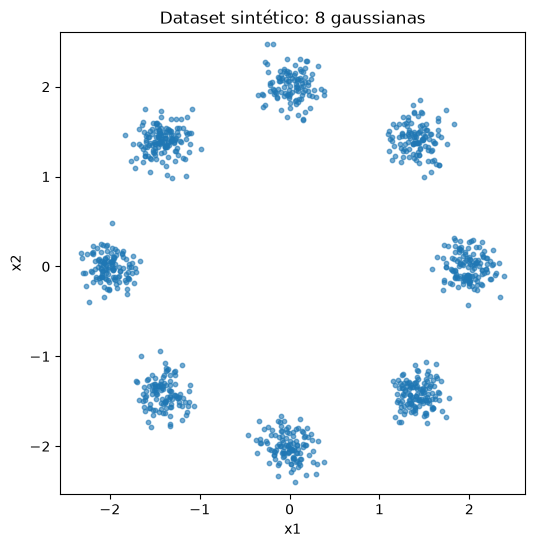

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(
    data[:, 0],
    data[:, 1],
    s=10,
    alpha=0.6,
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Dataset sintético: 8 gaussianas")
plt.axis("equal")
plt.show()

In [4]:
from ebm.data.toy import (
    sample_eight_gaussians,
    make_grid,
)

grid, xx, yy = make_grid(
    x_min=-4,
    x_max=4,
    y_min=-4,
    y_max=4,
    resolution=200,
)

print(grid.shape)
print(xx.shape)
print(yy.shape)

torch.Size([40000, 2])
torch.Size([200, 200])
torch.Size([200, 200])


In [5]:
import torch

In [6]:
with torch.no_grad():
    grid_energies = model(grid)

energy_map = grid_energies.reshape(xx.shape)

print(grid_energies.shape)
print(energy_map.shape)

torch.Size([40000])
torch.Size([200, 200])


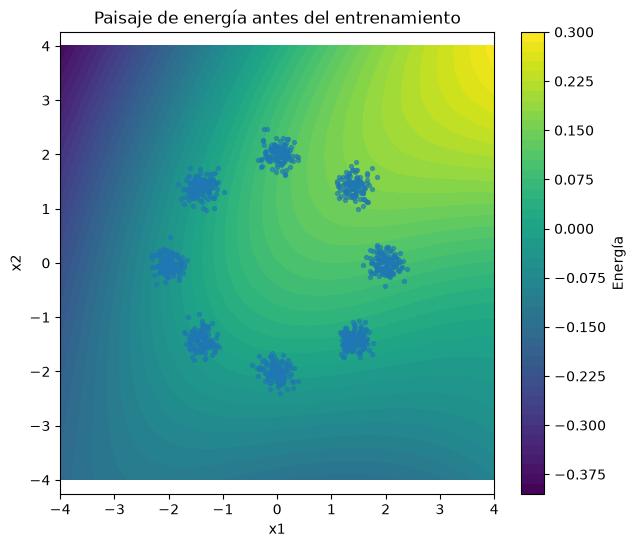

In [7]:
plt.figure(figsize=(7, 6))

contour = plt.contourf(
    xx.numpy(),
    yy.numpy(),
    energy_map.numpy(),
    levels=50,
)

plt.scatter(
    data[:, 0].numpy(),
    data[:, 1].numpy(),
    s=8,
    alpha=0.6,
)

plt.colorbar(
    contour,
    label="Energía",
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Paisaje de energía antes del entrenamiento")
plt.axis("equal")

plt.show()

In [ ]:
from ebm.sampling.langevin import langevin_sampling

x_init = 8 * torch.rand(200, 2) - 4

trajectory = langevin_sampling(
    model=model,
    x_init=x_init,
    n_steps=1000,
    step_size=0.05,
    noise_scale=0.01,
)
import ipywidgets as widgets
from IPython.display import display


def plot_langevin_step(step):

    points = trajectory[step]

    plt.figure(figsize=(7, 6))

    contour = plt.contourf(
        xx.numpy(),
        yy.numpy(),
        energy_map.numpy(),
        levels=50,
    )

    plt.scatter(
        points[:, 0].numpy(),
        points[:, 1].numpy(),
        s=15,
    )

    plt.colorbar(contour, label="Energía")

    plt.xlabel("x1")
    plt.ylabel("x2")

    plt.title(
        f"Langevin - paso {step}"
    )

    plt.xlim(-4, 4)
    plt.ylim(-4, 4)

    plt.show()

widgets.interact(
    plot_langevin_step,
    step=widgets.IntSlider(
        min=0,
        max=1000,
        step=1,
        value=0,
        description="Paso:",
    ),
)

/home/usuario/Documentos/TFG/entorno_tfg/lib/python3.12/site-packages/torch/autograd/graph.py:979: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12020). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


interactive(children=(IntSlider(value=0, description='Paso:', max=1000), Output()), _dom_classes=('widget-inte…

<function __main__.plot_langevin_step(step)>

Epoch 0 | Loss: 0.0907 | E_real: 0.0434 | E_model: -0.0473


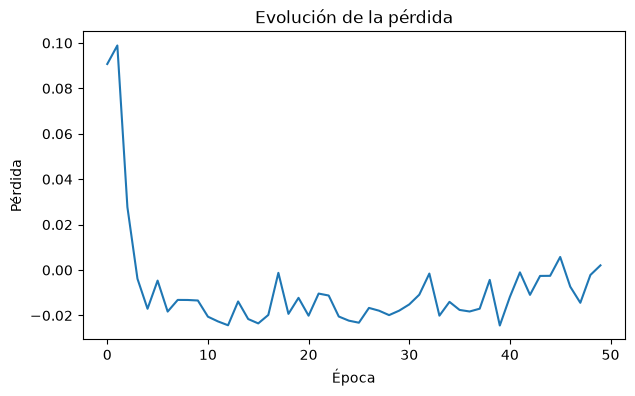

In [9]:
from ebm.training.train_toy import train_energy_model

model = EnergyModel()
losses = train_energy_model(
    model=model,
    data=data,
    n_epochs=50,
    batch_size=128,
    learning_rate=1e-3,
    langevin_steps=800,
    step_size=0.1,
    noise_scale=0.1,
)

plt.figure(figsize=(7, 4))

plt.plot(losses)

plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Evolución de la pérdida")

plt.show()

In [10]:
with torch.no_grad():
    grid_energies = model(grid)

energy_map = grid_energies.reshape(xx.shape)

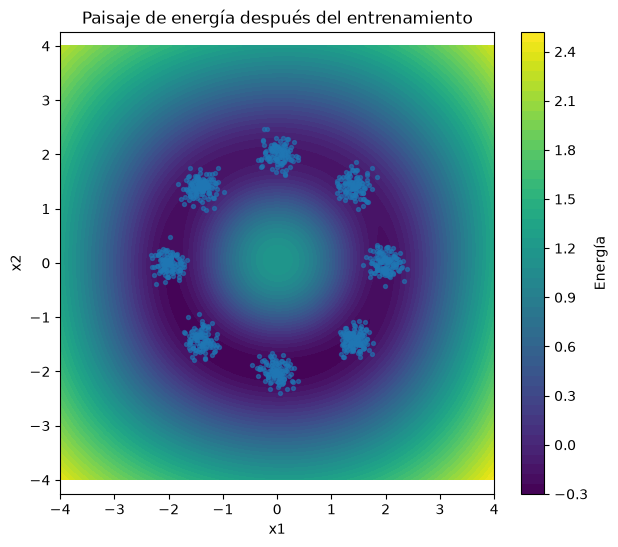

In [11]:
plt.figure(figsize=(7, 6))

contour = plt.contourf(
    xx.numpy(),
    yy.numpy(),
    energy_map.numpy(),
    levels=50,
)

plt.scatter(
    data[:, 0].numpy(),
    data[:, 1].numpy(),
    s=8,
    alpha=0.6,
)

plt.colorbar(contour, label="Energía")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Paisaje de energía después del entrenamiento")

plt.axis("equal")
plt.show()

In [12]:
from ebm.training.train_toy import train_energy_model_dsm

model_dsm = EnergyModel()

In [13]:
losses_dsm = train_energy_model_dsm(
    model=model_dsm,
    data=data,
    n_epochs=100,
    batch_size=128,
    learning_rate=1e-2,
    sigma=0.3,
)

Epoch 0 | Loss DSM: 22.4756
Epoch 10 | Loss DSM: 12.2972
Epoch 20 | Loss DSM: 9.4175
Epoch 30 | Loss DSM: 8.5658
Epoch 40 | Loss DSM: 9.2664
Epoch 50 | Loss DSM: 8.1091
Epoch 60 | Loss DSM: 8.6757
Epoch 70 | Loss DSM: 8.3490
Epoch 80 | Loss DSM: 8.7339
Epoch 90 | Loss DSM: 8.7906


In [14]:
with torch.no_grad():
    grid_energies_dsm = model_dsm(grid)

energy_map_dsm = grid_energies_dsm.reshape(xx.shape)

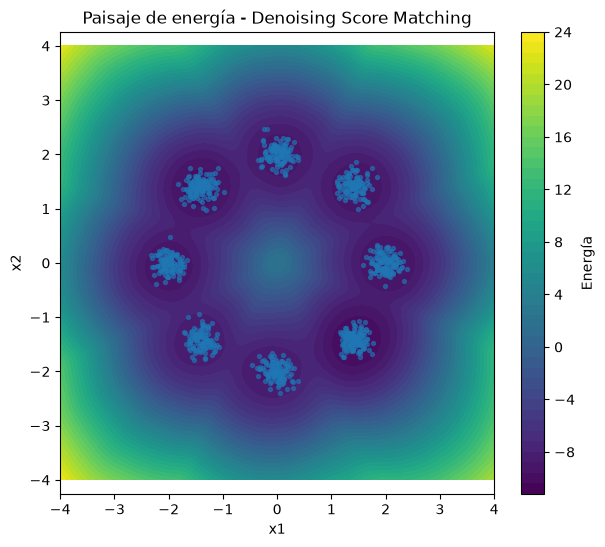

In [15]:
plt.figure(figsize=(7, 6))

contour = plt.contourf(
    xx.numpy(),
    yy.numpy(),
    energy_map_dsm.numpy(),
    levels=50,
)

plt.scatter(
    data[:, 0].numpy(),
    data[:, 1].numpy(),
    s=8,
    alpha=0.6,
)

plt.colorbar(
    contour,
    label="Energía",
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Paisaje de energía - Denoising Score Matching")

plt.axis("equal")
plt.show()

Epoch 0 | Loss PCD: 0.0825 | E_real: 0.1728 | E_model: 0.0192
Epoch 10 | Loss PCD: 0.0761 | E_real: -0.1210 | E_model: -0.1881
Epoch 20 | Loss PCD: 0.0621 | E_real: -0.2321 | E_model: -0.2895
Epoch 30 | Loss PCD: 0.0869 | E_real: -0.2813 | E_model: -0.3813
Epoch 40 | Loss PCD: 0.0723 | E_real: -0.2730 | E_model: -0.3425
Epoch 50 | Loss PCD: 0.0671 | E_real: -0.2729 | E_model: -0.3304
Epoch 60 | Loss PCD: 0.0465 | E_real: -0.2280 | E_model: -0.2618
Epoch 70 | Loss PCD: 0.0684 | E_real: -0.2298 | E_model: -0.2818
Epoch 80 | Loss PCD: 0.0343 | E_real: -0.2032 | E_model: -0.2430
Epoch 90 | Loss PCD: 0.0503 | E_real: -0.4343 | E_model: -0.4967


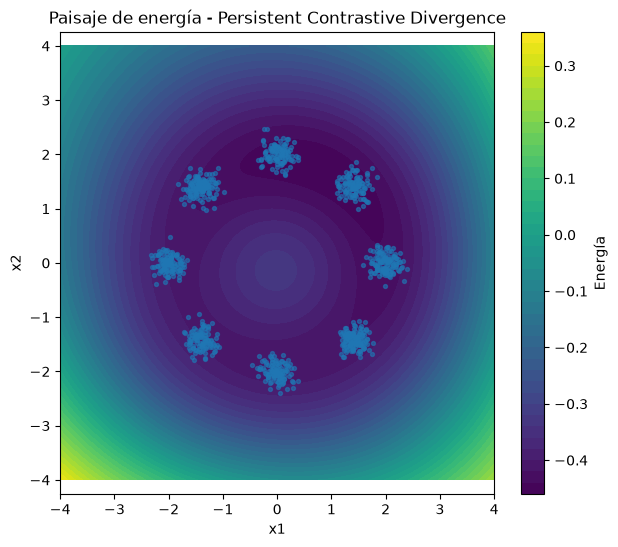

In [18]:
from ebm.training.train_toy import train_energy_model_pcd

model_pcd = EnergyModel()


losses_pcd, persistent_samples = train_energy_model_pcd(
    model=model_pcd,
    data=data,
    n_epochs=100,
    batch_size=128,
    learning_rate=1e-3,
    langevin_steps=100,
    step_size=0.1,
    noise_scale=0.01,
)

with torch.no_grad():
    grid_energies_pcd = model_pcd(grid)

energy_map_pcd = grid_energies_pcd.reshape(xx.shape)


plt.figure(figsize=(7, 6))

contour = plt.contourf(
    xx.numpy(),
    yy.numpy(),
    energy_map_pcd.numpy(),
    levels=50,
)

plt.scatter(
    data[:, 0].numpy(),
    data[:, 1].numpy(),
    s=8,
    alpha=0.6,
)

plt.colorbar(
    contour,
    label="Energía",
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Paisaje de energía - Persistent Contrastive Divergence")

plt.axis("equal")
plt.show()